<a href="https://colab.research.google.com/github/naganw/ML_PRACTICES/blob/main/practice7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print("Количество строк и столбцов:", df.shape)
print("Количество пассажиров:", df.shape[0])
print("Количество признаков:", df.shape[1])

Количество строк и столбцов: (891, 12)
Количество пассажиров: 891
Количество признаков: 12


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
missing_values = df.isnull().sum()

print("Количество пропусков по столбцам:")
print(missing_values)

Количество пропусков по столбцам:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
missing_percent = (df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({
    "Пропуски": df.isnull().sum(),
    "Пропуски, %": missing_percent
})

missing_table = missing_table.sort_values(
    by="Пропуски",
    ascending=False
)

display(missing_table)

,Пропуски,"Пропуски, %"
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


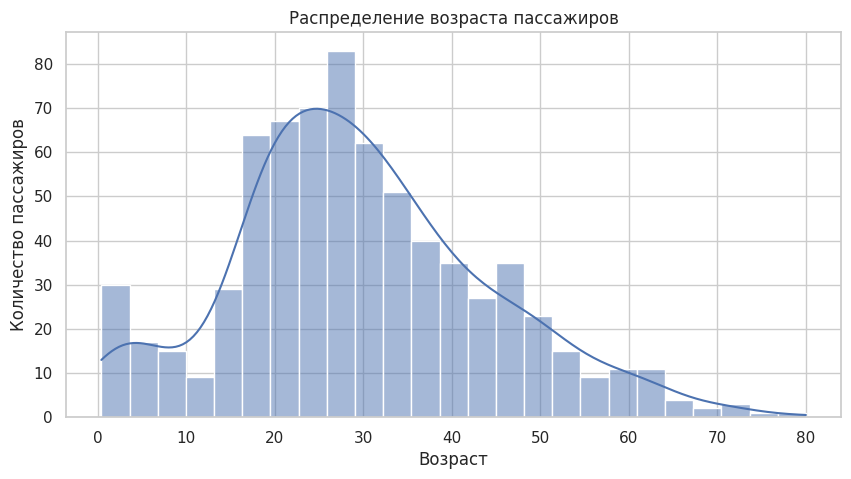

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=25,
    kde=True
)

plt.title("Распределение возраста пассажиров")
plt.xlabel("Возраст")
plt.ylabel("Количество пассажиров")

plt.show()

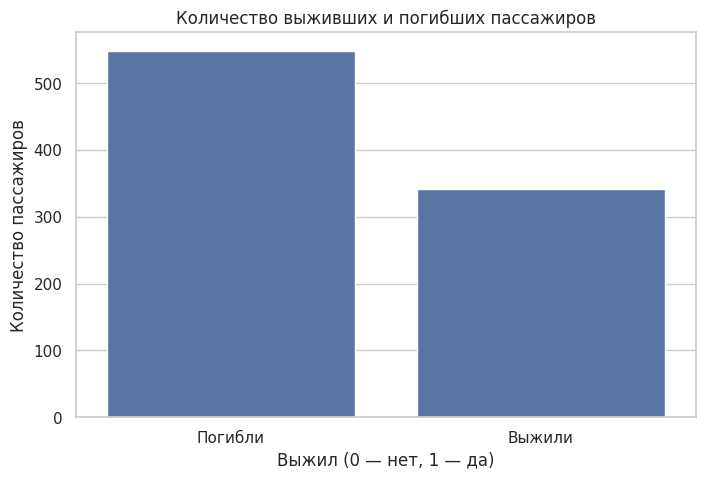

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Survived"
)

plt.title("Количество выживших и погибших пассажиров")
plt.xlabel("Выжил (0 — нет, 1 — да)")
plt.ylabel("Количество пассажиров")

plt.xticks(
    ticks=[0, 1],
    labels=["Погибли", "Выжили"]
)

plt.show()

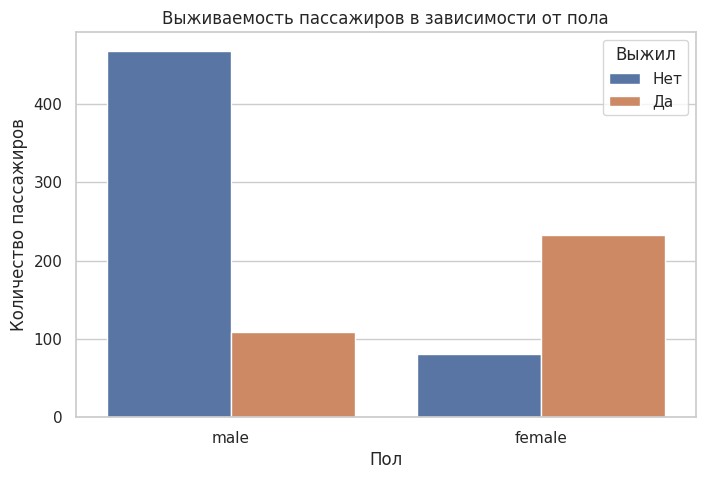

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sex",
    hue="Survived"
)

plt.title("Выживаемость пассажиров в зависимости от пола")
plt.xlabel("Пол")
plt.ylabel("Количество пассажиров")

plt.legend(
    title="Выжил",
    labels=["Нет", "Да"]
)

plt.show()

Выживаемость по полу, %:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


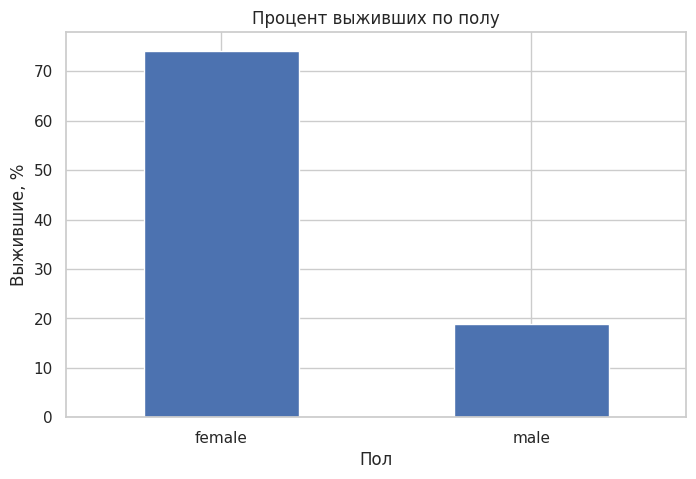

In [ ]:
survival_rate = df.groupby("Sex")["Survived"].mean() * 100

print("Выживаемость по полу, %:")
print(survival_rate.round(2))

survival_rate.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Процент выживших по полу")
plt.xlabel("Пол")
plt.ylabel("Выжившие, %")
plt.xticks(rotation=0)

plt.show()